# 1. The Roofline Model

By [Arun Sharma](https://arunshar.com) and [Claude Code](https://claude.com/claude-code)

This lecture looks at two limits on how fast a kernel can run on a processor. Either the
arithmetic units are already busy on every cycle, or main memory cannot deliver data fast
enough to keep those units busy. The **roofline model**
([Williams et al., CACM '09](https://doi.org/10.1145/1498765.1498785)) tells you which limit
applies and how fast the kernel can possibly run. It needs only two counts that you can do on
paper.

> Suppose a profiler on an NVIDIA A100 shows a large matrix multiply running at 250 TFLOP/s
> and the addition of two long vectors running at 0.3 TFLOP/s. Is the vector addition badly
> written?

By the end of this lecture you can answer that question with one multiplication. The model
rests on four quantities.

**Arithmetic intensity**
: Arithmetic intensity is the number of floating-point operations (FLOPs) a kernel performs
  for each byte it moves between main memory and the chip. Its unit is FLOP per byte.

**Peak compute**
: Peak compute is the largest number of FLOPs the chip can execute per second, in FLOP/s.

**Peak memory bandwidth**
: Peak memory bandwidth is the largest number of bytes main memory can deliver per second,
  in bytes/s.

**Ridge point**
: The ridge point is the arithmetic intensity at which the two limits are equal. It equals
  peak compute divided by peak memory bandwidth.

In this lecture you will count the arithmetic intensity of four common kernels, draw the
roofline of an A100, and then measure a roofline for the CPU that runs this notebook.

:::{admonition} Learning goals
- Compute a kernel's arithmetic intensity from its FLOP and byte counts.
- Predict a kernel's attainable FLOP/s with the roofline formula, and find the ridge point.
- Classify a kernel as memory-bound or compute-bound, and explain how reusing data moves it
  toward the ridge.
- Measure a roofline for one CPU core and test kernels against it.
:::

## Setup

Use the **Open in Colab** or **Launch Binder** button above this page to run the notebook
with nothing installed, or follow {doc}`../getting-started/run-locally`. The first cell loads
the course's helper module and sets up the plots, which takes a few seconds.

:::{note}
The GPU numbers in this lecture are NVIDIA's published peaks. The model only does arithmetic
with these numbers, so no GPU is needed. The last section times real code on the CPU that
runs this notebook. Those timings change from run to run and from machine to machine, so
treat them as approximate.
:::

In [1]:
import pathlib, sys, urllib.request

# The course keeps its helper module in labs/, two folders above this notebook.
HELPERS = pathlib.Path("../../labs").resolve()
if (HELPERS / "tutorial_helpers.py").exists():
    sys.path.insert(0, str(HELPERS))
else:  # On Colab, or in a notebook copied out of the course, the cell downloads the helper.
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/arunshar/roofline-tutorial/main/labs/tutorial_helpers.py",
        "tutorial_helpers.py")
import tutorial_helpers as th

import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (6.4, 3.6), "axes.grid": True, "grid.linestyle": ":"})

import numpy as np
import pandas as pd

## The system we study

The GPU examples use one NVIDIA A100-80GB in the SXM form factor, with the peaks from
[NVIDIA's data sheet](https://www.nvidia.com/en-us/data-center/a100/).

| | A100-80GB SXM |
|---|---|
| Peak dense BF16 compute (tensor cores) | 312 TFLOP/s |
| Peak FP32 compute (general-purpose cores) | 19.5 TFLOP/s |
| Memory (HBM2e) bandwidth | 2,039 GB/s |
| Memory capacity | 80 GB |

All data in the GPU examples is 16-bit BF16, so each value takes 2 bytes. We keep these
values in one constant, so every GPU experiment below uses the same system.

In [2]:
SYSTEM = dict(name="A100-80GB SXM", peak_flops=312e12, bandwidth=2.039e12, bytes_per_value=2)

## Two ceilings

Suppose a kernel performs $F$ FLOPs and moves $Q$ bytes to and from main memory. The chip
needs at least $F/P$ seconds for the arithmetic, where $P$ is peak compute. It also needs at
least $Q/\beta$ seconds to move the data, where $\beta$ is peak bandwidth. If the two
activities overlap perfectly, the kernel takes the longer of the two times. Dividing $F$ by
that time gives the most FLOP/s the kernel can reach:

$$
\text{attainable FLOP/s} = \min\left(P,\; I \times \beta\right), \qquad I = \frac{F}{Q}
$$

The next cell writes this formula as a function and draws it for the A100 on log-log axes.

ridge point: 153.0 FLOP/byte


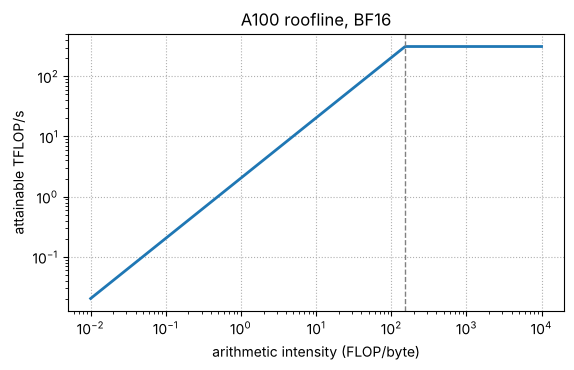

In [3]:
def attainable(intensity, system):
    """Return the roofline bound in FLOP/s for an arithmetic intensity in FLOP/byte."""
    return np.minimum(system["peak_flops"], np.asarray(intensity) * system["bandwidth"])


def ridge_point(system):
    """Return the intensity, in FLOP/byte, where the bandwidth and compute limits meet."""
    return system["peak_flops"] / system["bandwidth"]


def draw_roofline(system, ax=None, label=None):
    """Draw the roofline of a system on log-log axes, in TFLOP/s, and return the axes."""
    ax = ax or plt.gca()
    x = np.logspace(-2, 4, 400)
    ax.loglog(x, attainable(x, system) / 1e12, lw=2, label=label or system["name"])
    ax.set(xlabel="arithmetic intensity (FLOP/byte)", ylabel="attainable TFLOP/s")
    return ax


ax = draw_roofline(SYSTEM)
ax.axvline(ridge_point(SYSTEM), ls="--", color="gray", lw=1)
ax.set_title("A100 roofline, BF16")
print(f"ridge point: {ridge_point(SYSTEM):.1f} FLOP/byte")

The plot has two parts.

- **The slanted roof**, left of the ridge, is where memory bandwidth sets the speed. A kernel
  here is **memory-bound**. Its attainable FLOP/s grows in proportion to its intensity, so
  doubling the intensity doubles the bound.
- **The flat roof**, right of the ridge, is where the tensor cores are saturated. A kernel
  here is **compute-bound**, and more intensity does not raise its bound.

The ridge point is **~153 FLOP per byte**. A BF16 kernel on this A100 must do about 153 FLOPs
for every byte it moves before the tensor cores can run at full speed.

## Counting FLOPs and bytes

To place a kernel on the plot, count its FLOPs and the bytes it must move. We count each
input value read once and each output value written once. That is the least traffic the
kernel can generate, so the count gives the most optimistic intensity. Real kernels usually
move more bytes. They move fewer only when an input is still in cache from an earlier kernel,
and every large array here is bigger than the A100's 40 MB L2 cache.

| Kernel | Size | FLOPs | Values moved |
|---|---|---|---|
| Vector add, $c = a + b$ | $n = 10^8$ | $n$ | $3n$ |
| 5-point stencil (average of a cell and its 4 neighbors) | $8{,}192 \times 8{,}192$ raster | $5$ per cell | $2$ per cell |
| Matrix-vector product, $y = Wx$ | $W$ is $8{,}192 \times 8{,}192$ | $2mk$ | $mk + k + m$ |
| Matrix multiply, $C = AB$ | $N = 4{,}096$, square | $2N^3$ | $3N^2$ |

The stencil is the operation behind raster smoothing and one explicit step of the heat
equation. Its count assumes that each cell is read from memory once, with the neighbors
reused from the cache.

In [4]:
def kernel_costs(v=SYSTEM["bytes_per_value"]):
    """Return FLOPs and bytes moved for the four example kernels."""
    n = 10**8
    cells = 8192 * 8192
    m = k = 8192
    N = 4096
    return {
        "vector add": (n, 3 * n * v),
        "5-point stencil": (5 * cells, 2 * cells * v),
        "matrix-vector": (2 * m * k, (m * k + k + m) * v),
        "matrix multiply": (2 * N**3, 3 * N**2 * v),
    }


rows = []
for name, (flops, nbytes) in kernel_costs().items():
    intensity = flops / nbytes
    bound = attainable(intensity, SYSTEM)
    rows.append({"kernel": name,
                 "FLOP/byte": round(intensity, 3),
                 "attainable TFLOP/s": round(bound / 1e12, 2),
                 "share of peak": f"{bound / SYSTEM['peak_flops']:.1%}",
                 "limited by": "memory" if intensity < ridge_point(SYSTEM) else "compute",
                 "time (ms)": round(1e3 * flops / bound, 3)})
kernels = pd.DataFrame(rows).set_index("kernel")
kernels

,FLOP/byte,attainable TFLOP/s,share of peak,limited by,time (ms)
kernel,,,,,
vector add,0.167,0.34,0.1%,memory,0.294
5-point stencil,1.250,2.55,0.8%,memory,0.132
matrix-vector,1.000,2.04,0.7%,memory,0.066
matrix multiply,1365.333,312.00,100.0%,compute,0.441


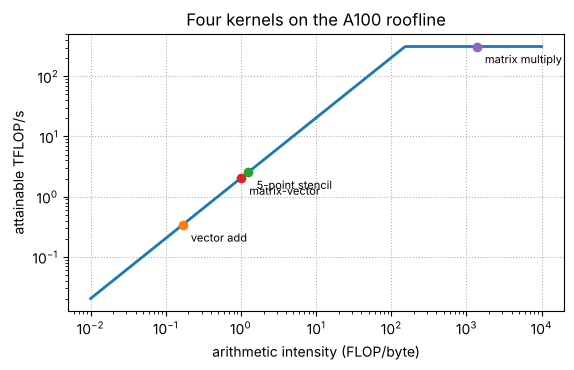

In [5]:
ax = draw_roofline(SYSTEM)
for name, row in kernels.iterrows():
    ax.plot(row["FLOP/byte"], row["attainable TFLOP/s"], "o")
    ax.annotate(name, (row["FLOP/byte"], row["attainable TFLOP/s"]),
                textcoords="offset points", xytext=(6, -12), fontsize=8)
ax.set_title("Four kernels on the A100 roofline");

The table gives three findings.

1. **The vector add does 1 FLOP for every 6 bytes.** Its intensity of ~0.17 FLOP/byte caps it
   at ~0.34 TFLOP/s, about 0.1% of peak. The 0.3 TFLOP/s in the opening scenario is therefore
   close to the best any implementation can reach, and the code is not the problem.
2. **The stencil and the matrix-vector product reach only about 1 FLOP per byte.** Both stay
   more than 100× below the ridge, so memory bandwidth sets their speed.
3. **Only the matrix multiply lies past the ridge.** Its intensity has a closed form,

   $$
   I = \frac{2N^3}{3N^2 \times 2\ \text{bytes}} = \frac{N}{3}\ \text{FLOP/byte},
   $$

   so at $N = 4{,}096$ it reaches ~1,365 FLOP/byte, about 9× the ridge. It can use the full
   312 TFLOP/s.

In [6]:
N = 4096
print(f"matrix multiply: N/3 = {N / 3:.1f} FLOP/byte, counted = {kernels.loc['matrix multiply', 'FLOP/byte']:.1f} FLOP/byte")
print(f"square BF16 matrix multiply at the ridge: N = 3 × ridge ≈ {3 * ridge_point(SYSTEM):.0f}")

matrix multiply: N/3 = 1365.3 FLOP/byte, counted = 1365.3 FLOP/byte
square BF16 matrix multiply at the ridge: N = 3 × ridge ≈ 459


The closed form matches the count in the table. The second line shows that a square BF16
matrix multiply needs $N$ of about 459 before it can reach the flat roof on this A100.

:::{warning}
**This lecture uses one compute ceiling.** The A100 runs element-wise kernels such as the
vector add on its general-purpose cores. Their peak is 19.5 TFLOP/s in FP32 and 39 TFLOP/s for
BF16 math. Only matrix arithmetic runs on the 312 TFLOP/s tensor cores. A complete roofline
draws one flat line for each kind of unit. The memory-bound kernels here sit far below every
flat line, so their classification does not change.
:::

:::{admonition} Try it
:class: exercise
1. **Add a second ceiling.** Draw a flat line at 19.5 TFLOP/s for FP32 work on the
   general-purpose cores, with the same bandwidth. Before you run it, predict the ridge point
   of that line. (Hint: divide the new peak by the same bandwidth.)
2. **Remove the cache.** Suppose the chip kept nothing on chip, so the stencil had to read all
   5 values of each cell from memory and then write 1. Recompute the stencil's intensity and
   predict its new attainable TFLOP/s. (Hint: count 6 values of 2 bytes per cell.)

Keep any new system in its own variable, so later cells still use `SYSTEM`.
:::

## Reuse moves a kernel to the right

The matrix-vector product reads each weight once and uses it for one multiply-add.
Multiplying the same matrix by a batch of $B$ vectors at once reuses each weight $B$ times.
The FLOPs grow $B$-fold, while the bytes barely change as long as the vectors are small next
to the matrix:

$$
I(B) = \frac{2mkB}{2\,(mk + kB + mB)} \approx B \quad \text{when } B \ll m, k
$$

The next cell sweeps the batch size for the $8{,}192 \times 8{,}192$ matrix.

In [7]:
def batched_matvec(batch, m=8192, k=8192, v=SYSTEM["bytes_per_value"]):
    """Return FLOPs and bytes moved for one m x k matrix times a batch of vectors."""
    flops = 2 * m * k * batch
    nbytes = (m * k + k * batch + m * batch) * v
    return flops, nbytes


rows = []
for batch in [1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]:
    flops, nbytes = batched_matvec(batch)
    bound = attainable(flops / nbytes, SYSTEM)
    rows.append({"batch": batch,
                 "FLOP/byte": round(flops / nbytes, 1),
                 "attainable TFLOP/s": round(bound / 1e12, 1),
                 "time per vector (µs)": round(1e6 * flops / bound / batch, 2)})
sweep = pd.DataFrame(rows).set_index("batch")

# Solving I(B) = R for B gives the batch at which the intensity equals the ridge point.
m = k = 8192
R = ridge_point(SYSTEM)
batch_at_ridge = R * m * k / (m * k - R * (m + k))
print(f"batch at the ridge: {batch_at_ridge:.0f}")
sweep

batch at the ridge: 159


,FLOP/byte,attainable TFLOP/s,time per vector (µs)
batch,,,
1,1.0,2.0,65.84
2,2.0,4.1,32.93
4,4.0,8.1,16.47
8,8.0,16.3,8.24
16,15.9,32.5,4.13
32,31.8,64.7,2.07
64,63.0,128.5,1.04
128,124.1,253.1,0.53
256,240.9,312.0,0.43


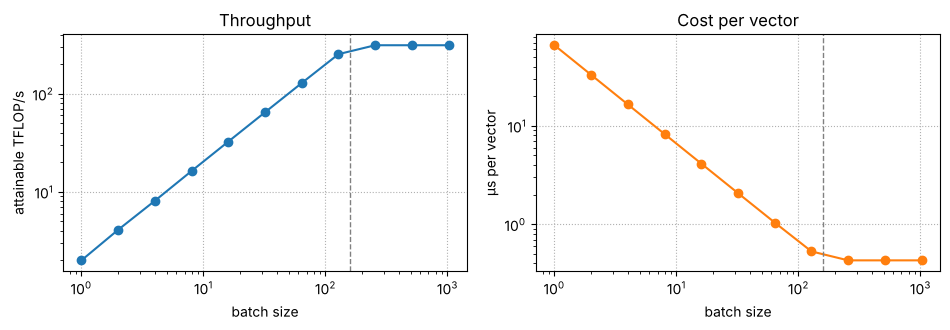

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(9.6, 3.4))
ax[0].loglog(sweep.index, sweep["attainable TFLOP/s"], "o-")
ax[0].axvline(batch_at_ridge, ls="--", color="gray", lw=1)
ax[0].set(xlabel="batch size", ylabel="attainable TFLOP/s", title="Throughput")
ax[1].loglog(sweep.index, sweep["time per vector (µs)"], "o-", color="C1")
ax[1].axvline(batch_at_ridge, ls="--", color="gray", lw=1)
ax[1].set(xlabel="batch size", ylabel="µs per vector", title="Cost per vector")
fig.tight_layout()

**Batching moves the kernel to the right along the slanted roof, by about 1 FLOP per byte
for each extra vector.** The two panels show both sides of that move.

- **Below the ridge**, the matrix is read once per batch, so each extra vector adds FLOPs but
  almost no memory traffic. The time per vector falls from ~66 µs at a batch of 1 to under
  1 µs at a batch of 128.
- **Past the ridge**, at a batch of about 159, the tensor cores are saturated. Throughput
  stays at 312 TFLOP/s, and the time per vector levels off at ~0.43 µs.

Tiling inside a matrix multiply works the same way. Each value loaded into on-chip memory is
reused across a whole tile. A $t \times t$ tile reuses each loaded value $t$ times, so the
intensity grows in proportion to the tile's edge length $t$.

:::{admonition} Try it
:class: exercise
**Try a faster GPU.** An H100 SXM peaks at about 989 TFLOP/s of dense BF16 compute and
3.35 TB/s of bandwidth. Store it in a new variable, such as `H100 = dict(...)` with the keys
`name`, `peak_flops` and `bandwidth`, and predict its ridge point and the batch it needs. Then
replace `SYSTEM` with `H100` in the two places it appears in the sweep cell, and rerun that
cell and the plot cell after it. (Hint: compute rises ~3.2× while bandwidth rises only ~1.6×.)
:::

## Measuring a roofline on this CPU

The same model applies to the CPU that runs this notebook. We do not know its exact peaks,
so we measure each ceiling with a kernel that the ceiling clearly limits.

- **The slanted roof:** A dot product of two long FP32 vectors reads 8 bytes for every
  2 FLOPs, an intensity of 0.25 FLOP/byte. One core's rate of pulling data from main memory
  sets its time, so its byte rate is our one-core bandwidth ceiling. One core usually cannot
  use all of the memory system's bandwidth, so this ceiling sits below the chip's.
- **The flat roof:** A $2{,}048 \times 2{,}048$ FP32 matrix multiply has an intensity of
  $N/6 \approx 341$ FLOP/byte, far to the right of any CPU ridge. Its FLOP rate is our
  compute ceiling. This ceiling is a lower bound on the true peak, because no real code
  reaches the hardware peak exactly.

We limit NumPy's math library to one thread, so both ceilings and every kernel run on one
core at a time. Each vector takes 192 MB, and the dot product reads two of them, 384 MB in
all. That is larger than the last-level cache of most machines, so the data comes from main
memory.

In [9]:
import time
from contextlib import nullcontext

try:
    from threadpoolctl import threadpool_limits
except ImportError:  # Without threadpoolctl, the matrix code may use every core.
    print("threadpoolctl is missing, so the matrix kernels may use every core. The compute "
          "ceiling will then not be a one-core number, and the matrix-vector product can land "
          "several times above the one-core roof. Run `pip install threadpoolctl` and restart "
          "the kernel.")
    threadpool_limits = lambda limits: nullcontext()


def one_core():
    """Limit NumPy's math library to one thread inside a with block."""
    return threadpool_limits(1)


def best_time(fn, repeats=5):
    """Run fn once to warm up, then return the fastest of several timed runs, in seconds."""
    fn()
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        fn()
        times.append(time.perf_counter() - start)
    return min(times)


with one_core():
    n = 48_000_000                                   # Each FP32 vector takes 192 MB.
    a = np.ones(n, np.float32)
    b = np.ones(n, np.float32)
    bandwidth = 8 * n / best_time(lambda: np.dot(a, b))
    A = np.ones((2048, 2048), np.float32)
    peak = 2 * 2048**3 / best_time(lambda: A @ A, repeats=3)

CPU = dict(name="one CPU core", peak_flops=peak, bandwidth=bandwidth)
print(f"bandwidth ceiling: {bandwidth / 1e9:.1f} GB/s")
print(f"compute ceiling:   {peak / 1e9:.0f} GFLOP/s")
print(f"ridge point:       {ridge_point(CPU):.1f} FLOP/byte")

bandwidth ceiling: 14.1 GB/s
compute ceiling:   131 GFLOP/s
ridge point:       9.3 FLOP/byte


Now we test two kernels that were not used to measure the ceilings. A vector add on FP32
data does 1 FLOP per 12 bytes, and a matrix-vector product on FP32 data does about 2 FLOPs
per 4 bytes. The matrix takes 340 MB, which is again larger than most caches.

In [10]:
with one_core():
    c = np.empty(n, np.float32)
    t_add = best_time(lambda: np.add(a, b, out=c), repeats=10)
    del a, b, c
    W = np.ones((9216, 9216), np.float32)
    x = np.ones(9216, np.float32)
    t_mv = best_time(lambda: W @ x, repeats=10)
    del W

tests = {
    "vector add": (n, 12 * n, t_add),
    "matrix-vector": (2 * 9216**2, 4 * (9216**2 + 2 * 9216), t_mv),
}
rows = []
for name, (flops, nbytes, seconds) in tests.items():
    predicted = attainable(flops / nbytes, CPU)
    rows.append({"kernel": name,
                 "FLOP/byte": round(flops / nbytes, 3),
                 "predicted GFLOP/s": round(predicted / 1e9, 2),
                 "measured GFLOP/s": round(flops / seconds / 1e9, 2),
                 "measured / predicted": round(flops / seconds / predicted, 2)})
measured = pd.DataFrame(rows).set_index("kernel")
measured

,FLOP/byte,predicted GFLOP/s,measured GFLOP/s,measured / predicted
kernel,,,,
vector add,0.083,1.18,1.00,0.85
matrix-vector,0.500,7.05,6.18,0.88


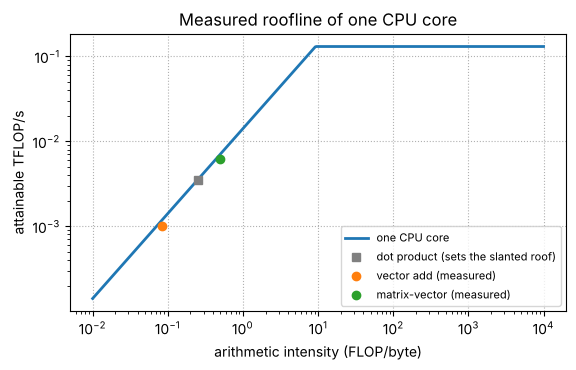

In [11]:
ax = draw_roofline(CPU)
ax.plot(0.25, bandwidth * 0.25 / 1e12, "s", color="gray", label="dot product (sets the slanted roof)")
for name, row in measured.iterrows():
    ax.plot(row["FLOP/byte"], row["measured GFLOP/s"] / 1e3, "o", label=f"{name} (measured)")
ax.set_title("Measured roofline of one CPU core")
ax.legend(fontsize=8, loc="lower right");

Your printed numbers will differ from mine. In my runs on a 4-core cloud machine, the
bandwidth ceiling was ~11 to ~15 GB/s and the compute ceiling was ~100 to ~180 GFLOP/s.
The ridge point fell between ~8 and ~14 FLOP/byte. That ridge is more than 10× lower than
the A100's BF16 ridge, and the tensor cores cause most of the gap. The A100's FP32 ridge on
its general-purpose cores is 19.5 / 2.039 ≈ 9.6 FLOP/byte, which falls inside the CPU core's
range.

**Both test kernels land within about a factor of 2 of the slanted roof that the dot product
measured, far below the flat roof.** In most of my runs, the measured / predicted column was
between ~0.7 and ~1.1, and in a few runs the vector add fell to ~0.5. A shared cloud machine
gives a slow run when other work uses the memory at the same time, so rerun the two
measurement cells if a ratio looks low. For these kernels, the bytes moved set the time, as the
model says.

The vector add is the stronger test, because it does different arithmetic and also writes its
result. The matrix-vector product is a stack of dot products, so it mainly checks the byte
count. A ratio a little above 1 does not break the model. Each measured ceiling is a lower
bound on the true peak, so another kernel can edge past it.

:::{note}
On most CPUs, a store that misses the cache first reads the cache line it is about to write,
which is called *write-allocate*. Streaming (non-temporal) stores skip that read. With
write-allocate, the vector add can move up to 16 bytes per element. That is a third more than
the 12 we counted, so its predicted rate would fall by a quarter. Counting the bytes your code
requests is a starting point, and a hardware profiler counts the bytes that actually move.
:::

:::{admonition} Try it
:class: exercise
**Use every core.** The dot product of two vectors runs on one thread whatever the limit, so
this exercise measures bandwidth with the matrix-vector product, which the math library
splits across threads. Copy the code below into a new cell. Before you run it, predict which
ceiling rises more and which way the ridge point moves. (Hint: on a laptop, one or two cores
can nearly fill the shared memory bus. A cloud machine may give each core its own share of the
bandwidth.)

```python
import os
with threadpool_limits(os.cpu_count()):
    W = np.ones((9216, 9216), np.float32)
    x = np.ones(9216, np.float32)
    bw_all = 4 * W.size / best_time(lambda: W @ x)
    A = np.ones((2048, 2048), np.float32)
    peak_all = 2 * 2048**3 / best_time(lambda: A @ A, repeats=3)
    del W
print(f"all cores: {bw_all / 1e9:.1f} GB/s, {peak_all / 1e9:.0f} GFLOP/s, "
      f"ridge {peak_all / bw_all:.1f} FLOP/byte")
```
:::

## Summary

| Kernel | Intensity (FLOP/byte) | On the A100 (ridge ~153 FLOP/byte) | What raises its intensity |
|---|---|---|---|
| Vector add | ~0.17 | memory-bound, at most ~0.34 TFLOP/s | Nothing inside the kernel raises it, because each value is used once. Fusing it with the kernels around it saves the trip to memory. |
| 5-point stencil | ~1.25 | memory-bound, at most ~2.5 TFLOP/s | Combining several time steps per pass raises it. The ~1.25 already assumes that the neighbors come from cache. |
| Matrix-vector product | ~1.0 | memory-bound, at most ~2.0 TFLOP/s | Batching vectors raises it, and a batch of about 159 reaches the ridge. |
| Matrix multiply, $N = 4{,}096$ | ~1,365 | compute-bound, up to 312 TFLOP/s | Nothing more is needed, because it already lies past the ridge. |

The roofline gives an upper bound from two counts and two hardware numbers, and a kernel far
below that bound needs a profiler to find the lost time. A kernel on the slanted roof speeds
up only when it moves fewer bytes, through more reuse or smaller data types, or when memory
gets faster. A kernel on the flat roof speeds up only when it does fewer FLOPs or runs on
faster arithmetic units.

## Check your understanding

Pick an answer to see whether it is right. After a wrong answer, you can try another option.

In [12]:
#@title Run this cell to show the quiz
th.quiz([
    {"q": "A kernel performs 1,000 FLOPs and moves 4,000 bytes. What is its arithmetic intensity?",
     "options": ["0.25 FLOP/byte", "4 FLOP/byte", "4,000 FLOP/byte"], "answer": 0,
     "explain": "Intensity is FLOPs divided by bytes, so it is 1,000 / 4,000 = 0.25 FLOP/byte."},
    {"q": "The A100 peaks at 312 TFLOP/s and 2.039 TB/s. Where is its ridge point?",
     "options": ["~15 FLOP/byte", "~153 FLOP/byte", "~1,530 FLOP/byte"], "answer": 1,
     "explain": "The ridge point is peak compute divided by bandwidth, so it is 312 / 2.039 ≈ 153 FLOP/byte."},
    {"q": "A kernel with an intensity of 10 FLOP/byte runs on the A100. What is its attainable rate?",
     "options": ["~20 TFLOP/s", "312 TFLOP/s", "~3 TFLOP/s"], "answer": 0,
     "explain": "It sits left of the ridge, so the bound is 10 × 2.039 TB/s ≈ 20.4 TFLOP/s."},
    {"q": "True or false: a vector add that reaches 0.3 TFLOP/s on an A100 is badly written.",
     "options": ["True", "False"], "answer": 1,
     "explain": "Its intensity is ~0.17 FLOP/byte, so no implementation can beat ~0.34 TFLOP/s on this GPU."},
    {"q": "A new chip doubles the memory bandwidth and keeps the same peak compute. The ridge point becomes…",
     "options": ["the same", "half as large", "twice as large"], "answer": 1,
     "explain": "The ridge point is peak compute divided by bandwidth, so doubling the bandwidth halves it."},
    {"q": "A 96 × 96 BF16 matrix multiply runs on the A100. Is it memory-bound or compute-bound?",
     "options": ["Memory-bound", "Compute-bound"], "answer": 0,
     "explain": "Its intensity is N/3 = 32 FLOP/byte, below the ridge of ~153. A square multiply needs N of about 459."},
    {"q": "Multiplying an 8,192 × 8,192 BF16 matrix by a batch of B vectors gives an intensity of about…",
     "options": ["1 FLOP/byte for any batch", "B FLOP/byte while B is small", "B<sup>2</sup> FLOP/byte"], "answer": 1,
     "explain": "Each weight is read once and reused B times, so the intensity grows to about B. The sweep shows ~124 FLOP/byte at a batch of 128, and the growth slows once the vectors stop being small."},
    {"q": "The vector add and the matrix-vector product ran at roughly the rate that the measured CPU roof predicted. What does that show?",
     "options": ["The bytes they move set their time, as the model says",
                 "The CPU's compute peak sets their time",
                 "The roofline model does not apply to CPUs"], "answer": 0,
     "explain": "Both kernels sit far left of the CPU ridge, which fell between ~8 and ~14 FLOP/byte in the lecture's runs, so the slanted roof bounds them."},
    {"q": "Why does the CPU measurement limit NumPy's math library to one thread?",
     "options": ["So that the ceilings and the test kernels use the same hardware",
                 "Because NumPy cannot use more than one core",
                 "Because timing runs faster on one thread"], "answer": 0,
     "explain": "NumPy's element-wise kernels and its dot product of two vectors use one thread, while the matrix kernels can use several. Limiting the math library to one thread keeps every measurement on one core at a time."},
])